In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller

In [3]:
df = pd.read_csv('../Renewable Energy Forecast/data/dataset.csv')
df.head()

,Entity,Year,Access to electricity (% of population),Access to clean fuels for cooking,Renewable-electricity-generating-capacity-per-capita,Financial flows to developing countries (US $),Renewable energy share in the total final energy consumption (%),Electricity from fossil fuels (TWh),Electricity from nuclear (TWh),Electricity from renewables (TWh),...,Primary energy consumption per capita (kWh/person),Energy intensity level of primary energy (MJ/$2017 PPP GDP),Value_co2_emissions_kt_by_country,Renewables (% equivalent primary energy),gdp_growth,gdp_per_capita,Density(P/Km2),Land Area(Km2),Latitude,Longitude
0,Afghanistan,2000,1.613591,6.2,9.22,20000.0,44.99,0.16,0.0,0.31,...,302.59482,1.64,760.000000,NaN,NaN,NaN,60,652230.0,33.93911,67.709953
1,Afghanistan,2001,4.074574,7.2,8.86,130000.0,45.60,0.09,0.0,0.50,...,236.89185,1.74,730.000000,NaN,NaN,NaN,60,652230.0,33.93911,67.709953
2,Afghanistan,2002,9.409158,8.2,8.47,3950000.0,37.83,0.13,0.0,0.56,...,210.86215,1.40,1029.999971,NaN,NaN,179.426579,60,652230.0,33.93911,67.709953
3,Afghanistan,2003,14.738506,9.5,8.09,25970000.0,36.66,0.31,0.0,0.63,...,229.96822,1.40,1220.000029,NaN,8.832278,190.683814,60,652230.0,33.93911,67.709953
4,Afghanistan,2004,20.064968,10.9,7.75,NaN,44.24,0.33,0.0,0.56,...,204.23125,1.20,1029.999971,NaN,1.414118,211.382074,60,652230.0,33.93911,67.709953


In [4]:
# Ubah semua ke kecil
df.columns = (df.columns.str.strip().str.lower().str.replace(r"[\n\r]+", " ", regex=True).str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
display(df.columns)

Index(['entity', 'year', 'access_to_electricity_of_population',
       'access_to_clean_fuels_for_cooking',
       'renewable_electricity_generating_capacity_per_capita',
       'financial_flows_to_developing_countries_us',
       'renewable_energy_share_in_the_total_final_energy_consumption',
       'electricity_from_fossil_fuels_twh', 'electricity_from_nuclear_twh',
       'electricity_from_renewables_twh', 'low_carbon_electricity_electricity',
       'primary_energy_consumption_per_capita_kwh_person',
       'energy_intensity_level_of_primary_energy_mj_2017_ppp_gdp',
       'value_co2_emissions_kt_by_country',
       'renewables_equivalent_primary_energy', 'gdp_growth', 'gdp_per_capita',
       'density_p_km2', 'land_area_km2', 'latitude', 'longitude'],
      dtype='str')

In [5]:
# Rename biar lebih singkat
df = df.rename(columns={
    'entity': 'country',
    'access_to_electricity_of_population': 'electricity_access',
    'access_to_clean_fuels_for_cooking': 'clean_fuel_access',
    'renewable_electricity_generating_capacity_per_capita': 'renewable_electricity_capita',
    'financial_flows_to_developing_countries_us': 'financial_flows',
    'renewable_energy_share_in_the_total_final_energy_consumption': 'renewable_share', 
    'electricity_from_fossil_fuels_twh': 'fossil_electricity', 
    'electricity_from_nuclear_twh': 'nuclear_electricity',
    'electricity_from_renewables_twh': 'renewable_electricity',
    'low_carbon_electricity_electricity' : 'low_carbon_electricity' ,
    'primary_energy_consumption_per_capita_kwh_person': 'energy_contumption_capita',
    'energy_intensity_level_of_primary_energy_mj_2017_ppp_gdp': 'energ_intensity',
    'value_co2_emissions_kt_by_country' : 'co2_emissions',
    'renewables_equivalent_primary_energy' : 'renewable_primary_energy',
    'density_p_km2' : 'people_density'
})

for col in df.columns:
    if col != "country" :
        df[col] = pd.to_numeric(df[col].astype("string").str.replace(",", "", regex=False), errors="coerce")
        df["year"] = df["year"].astype("Int64")
        
display(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 3649 entries, 0 to 3648
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   country                       3649 non-null   str    
 1   year                          3649 non-null   Int64  
 2   electricity_access            3639 non-null   Float64
 3   clean_fuel_access             3480 non-null   Float64
 4   renewable_electricity_capita  2718 non-null   Float64
 5   financial_flows               1560 non-null   Float64
 6   renewable_share               3455 non-null   Float64
 7   fossil_electricity            3628 non-null   Float64
 8   nuclear_electricity           3523 non-null   Float64
 9   renewable_electricity         3628 non-null   Float64
 10  low_carbon_electricity        3607 non-null   Float64
 11  energy_contumption_capita     3649 non-null   Float64
 12  energ_intensity               3442 non-null   Float64
 13  co2_emissions 

None

In [6]:
print(f"Total Rows {df.shape[0]}")
print(f"Total Columns {df.shape[1]}")
print(f"Missing Values {df.isnull().sum().sum()}")
print(f"Duplicated {df.duplicated().sum()}")
display(df.isnull().sum())

Total Rows 3649
Total Columns 21
Missing Values 6978
Duplicated 0


country                            0
year                               0
electricity_access                10
clean_fuel_access                169
renewable_electricity_capita     931
financial_flows                 2089
renewable_share                  194
fossil_electricity                21
nuclear_electricity              126
renewable_electricity             21
low_carbon_electricity            42
energy_contumption_capita          0
energ_intensity                  207
co2_emissions                    428
renewable_primary_energy        2137
gdp_growth                       317
gdp_per_capita                   282
people_density                     1
land_area_km2                      1
latitude                           1
longitude                          1
dtype: int64

In [7]:
df = df.drop_duplicates(subset=["country", "year"])
df = df.sort_values(["country", "year"]).reset_index(drop=True)
print("Jumlah negara:", df["country"].nunique())
print("Rentang tahun:", df["year"].min(), "-", df["year"].max())

Jumlah negara: 176
Rentang tahun: 2000 - 2020


In [8]:
df.describe()

,year,electricity_access,clean_fuel_access,renewable_electricity_capita,financial_flows,renewable_share,fossil_electricity,nuclear_electricity,renewable_electricity,low_carbon_electricity,energy_contumption_capita,energ_intensity,co2_emissions,renewable_primary_energy,gdp_growth,gdp_per_capita,people_density,land_area_km2,latitude,longitude
count,3649.0,3639.0,3480.0,2718.0,1560.0,3455.0,3628.0,3523.0,3628.0,3607.0,3649.0,3442.0,3221.0,1512.0,3332.0,3367.0,3648.0,3648.0,3648.0,3648.0
mean,2010.038367,78.933702,63.255287,113.137498,94224000.0,32.638165,70.365003,13.45019,23.96801,36.801182,25743.981745,5.307345,159866.462686,11.986707,3.44161,13283.774348,223.573191,633213.489309,18.246388,14.822695
std,6.054228,30.275541,39.043658,244.167256,298154406.585605,29.894901,348.051866,73.006623,104.431085,34.314884,34773.221366,3.53202,773661.064394,14.994644,5.68672,19709.866716,683.463448,1585519.216461,24.159232,66.348148
min,2000.0,1.252269,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.11,10.0,0.0,-62.07592,111.927225,2.0,21.0,-40.900557,-175.198242
25%,2005.0,59.80089,23.175,3.54,260000.0,6.515,0.29,0.0,0.04,2.877847,3116.7373,3.17,2019.999981,2.137095,1.383302,1337.813437,34.0,25713.0,3.202778,-11.779889
50%,2010.0,98.36157,83.15,32.91,5665000.0,23.3,2.97,0.0,1.47,27.865068,13120.57,4.3,10500.0,6.290766,3.559855,4578.633208,87.0,117600.0,17.189877,19.145136
75%,2015.0,100.0,100.0,112.21,55347500.0,55.245,26.8375,0.0,9.6,64.403792,33892.78,6.0275,60580.00183,16.841638,5.830099,15768.615365,219.0,513120.0,38.969719,46.199616
max,2020.0,100.0,100.0,3060.19,5202310000.0,96.04,5184.13,809.41,2184.94,100.00001,262585.7,32.57,10707219.73,86.836586,123.139555,123514.1967,8358.0,9984670.0,64.963051,178.065032


#### EDA

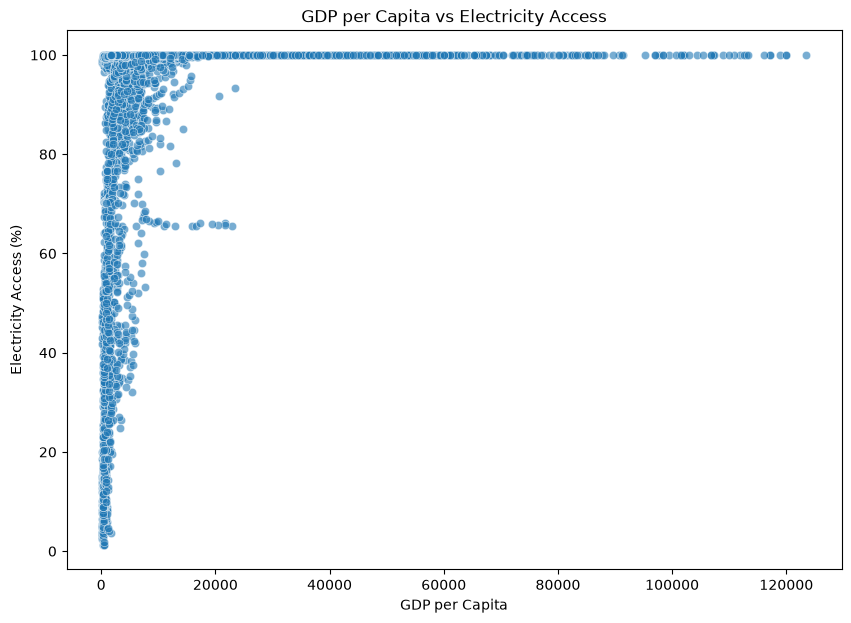

In [9]:
plt.figure(figsize=(10,7))
sns.scatterplot(data=df, x="gdp_per_capita", y="electricity_access", alpha=0.6)
plt.title("GDP per Capita vs Electricity Access")
plt.xlabel("GDP per Capita")
plt.ylabel("Electricity Access (%)")
plt.show()

Text(0, 0.5, 'Electricity Access')

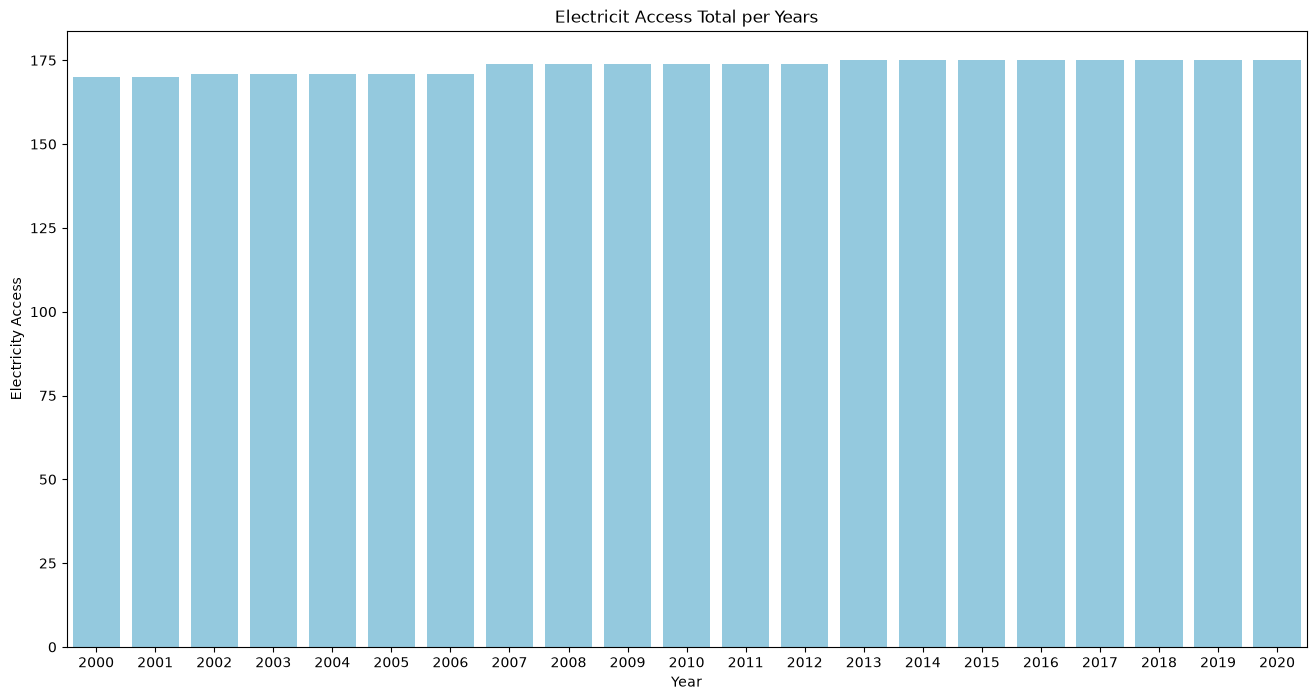

In [10]:
yearly_electricity_access = (df.groupby('year')['electricity_access'].count().reset_index())
plt.figure(figsize=(16,8))
sns.barplot(data=yearly_electricity_access, x='year', y='electricity_access', color='skyblue')
plt.title("Electricit Access Total per Years")
plt.xlabel("Year")
plt.ylabel("Electricity Access")

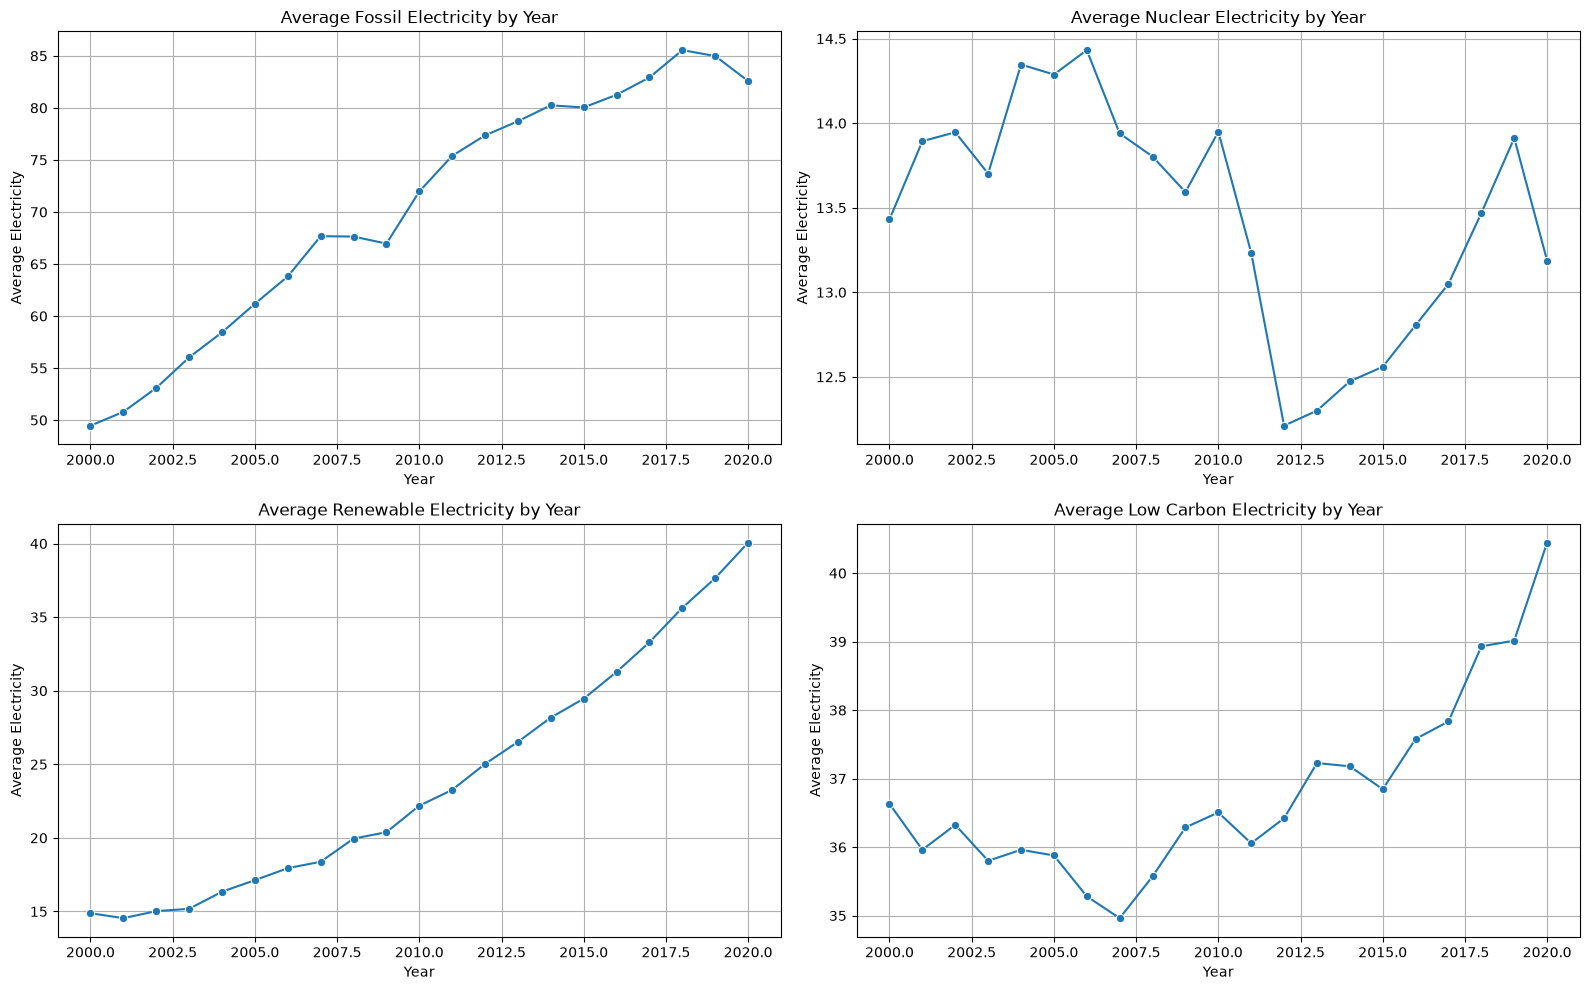

In [11]:
yearly_cols = ['fossil_electricity', 'nuclear_electricity', 'renewable_electricity','low_carbon_electricity']

fig, ax = plt.subplots(2,2, figsize=(16,10))
ax = ax.flatten()

for i, col in enumerate(yearly_cols):
    yearly_data = df.groupby('year')[col].mean().reset_index()
    sns.lineplot(data=yearly_data, x='year', y=col, marker='o', ax=ax[i] )

    ax[i].set_title(f'Average {col.replace("_", " ").title()} by Year')
    ax[i].set_xlabel('Year')
    ax[i].set_ylabel('Average Electricity')
    ax[i].grid(True)

plt.tight_layout()
plt.show()

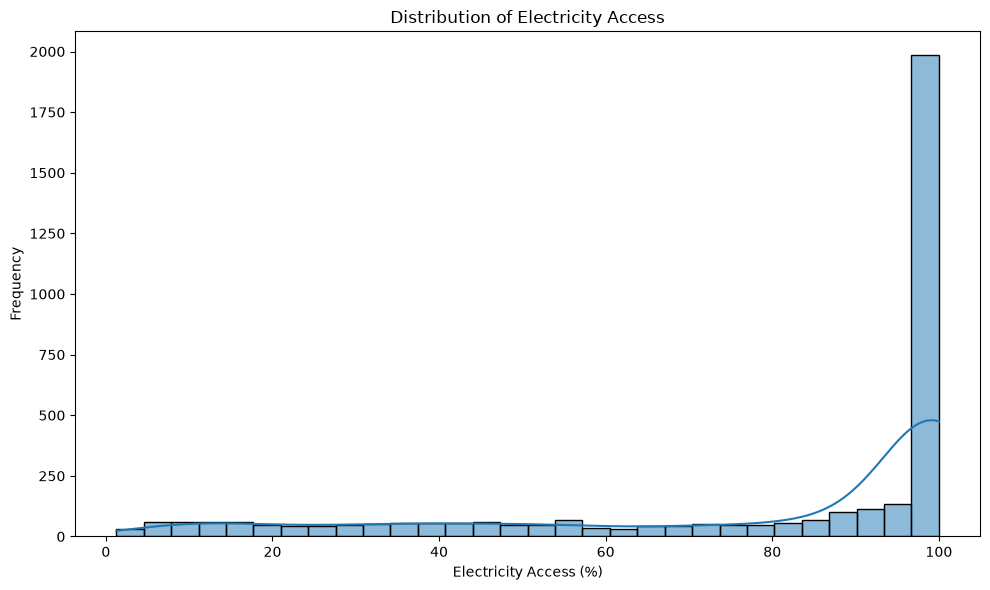

In [12]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='electricity_access', bins=30, kde=True)
plt.title('Distribution of Electricity Access')
plt.xlabel('Electricity Access (%)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

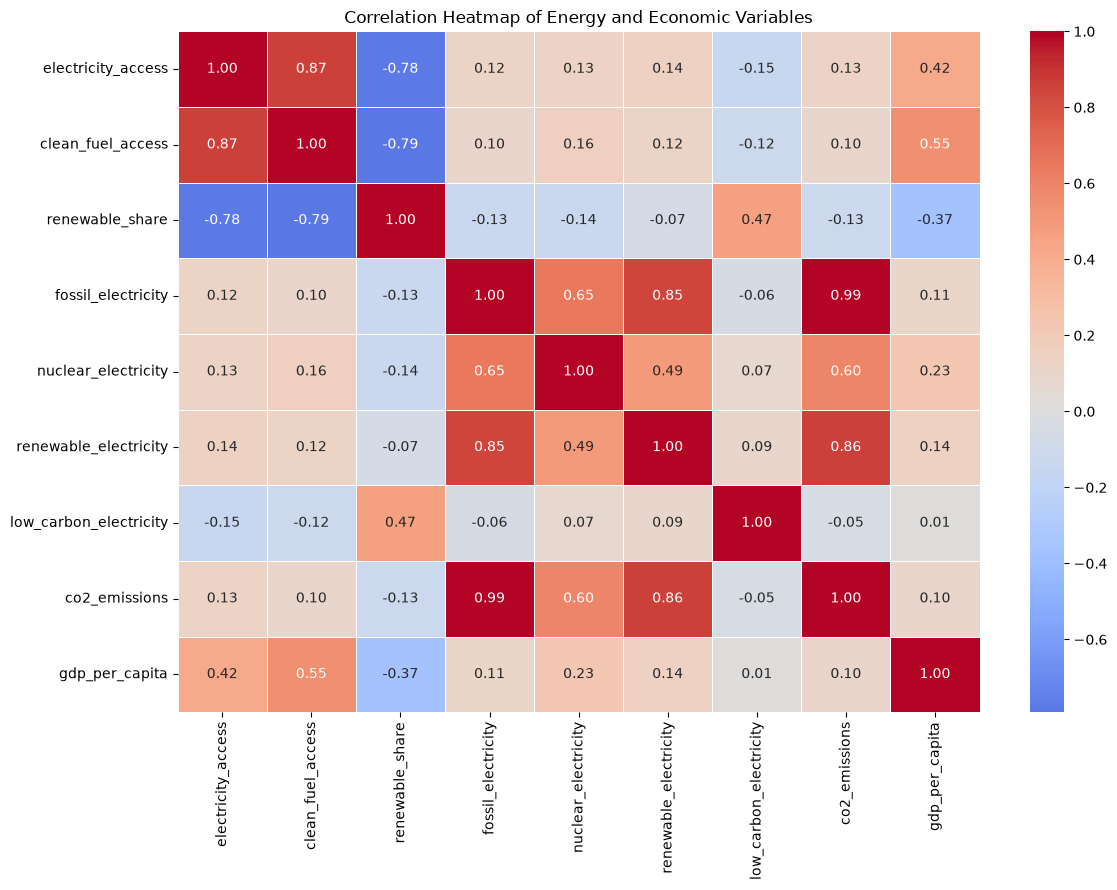

In [ ]:
corr_cols = [
    'electricity_access', 'clean_fuel_access', 'renewable_share',
    'fossil_electricity', 'nuclear_electricity',
    'renewable_electricity', 'low_carbon_electricity',
    'co2_emissions', 'gdp_per_capita'
]

corr_matrix = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Heatmap of Energy and Economic Variables')
plt.tight_layout()
plt.show()

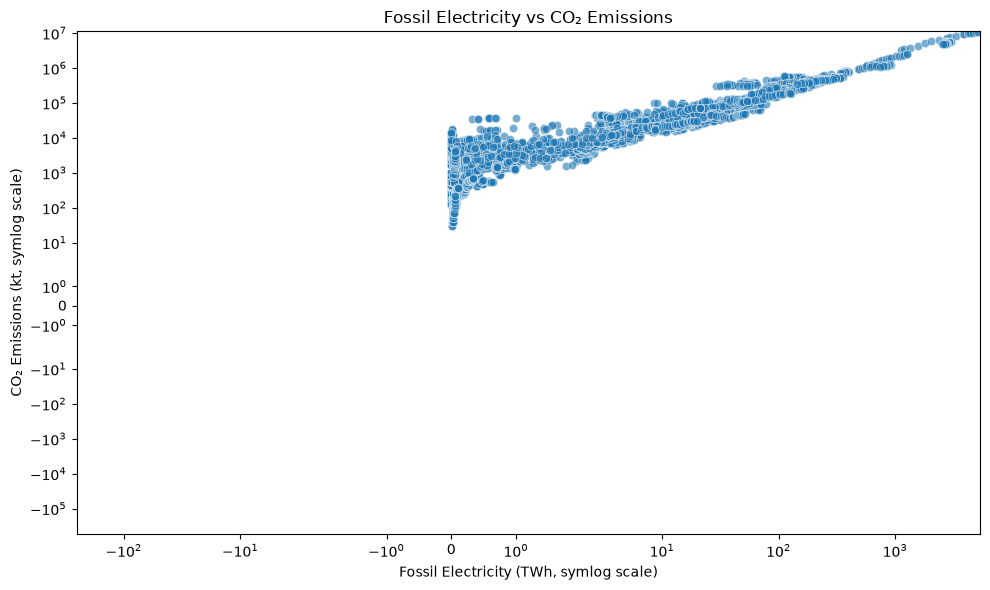

In [15]:
scatter_data = df[['fossil_electricity', 'co2_emissions']].dropna()
scatter_data = scatter_data[
    (scatter_data['fossil_electricity'] >= 0) &
    (scatter_data['co2_emissions'] >= 0)
]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=scatter_data, x='fossil_electricity', y='co2_emissions', alpha=0.6)
plt.xscale('symlog')
plt.yscale('symlog')
plt.title('Fossil Electricity vs CO₂ Emissions')
plt.xlabel('Fossil Electricity (TWh, symlog scale)')
plt.ylabel('CO₂ Emissions (kt, symlog scale)')
plt.tight_layout()
plt.show()

#### Preprocessing

In [ ]:
# Cek distribusi numerik 
numeric_cols = df.select_dtypes(include='number')

fig, ax = plt.subplot(4,4, figsize=(16,8))